# Envelope GPI on the real Office domain

Cells through "Part 2" are copied verbatim from `OKB/notebooks/office_rmvi_comparison.ipynb`
(Office env setup, exact tabular dynamics, the canonical corner-weight basis
`Pi_canon`/`W_canon` up to `k=d` policies, and the reference GPI/election/metapolicy
value functions used for Fig. `office_08_metavsokvsgpi`). `SFOLS/12_envelope_gpi_dst.ipynb`
already validated Theorem `thm:envelope` on the real, certified DST basis, but DST's
basis never grew past k=2 -- too small to see the k-dependence the cost argument is
about. Office's basis naturally reaches k=d=6 canonical corners, so this is the
right domain to test whether the asymptotic O(|A|d+k) vs O(k|A|d) claim shows up as a
real, measured wall-clock difference.

## Part 0/1/2 (verbatim from office_rmvi_comparison.ipynb): env setup, canonical basis

In [1]:
import os
os.environ["WANDB_MODE"] = "disabled"

import sys
OKB_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
SF_FSA_VI_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "RM", "sf-fsa-vi"))
for root in (OKB_ROOT, SF_FSA_VI_ROOT):
    if root not in sys.path:
        sys.path.insert(0, root)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import wandb
wandb.init(mode="disabled")

import gym as old_gym
import gymnasium as gym
from gymnasium import spaces
import envs  # noqa: F401 -- registers Office-v0 in old gym

from rl.successor_features.ols import OLS
from rl.utils.utils import seed_everything

%matplotlib inline

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/flax/configurations.py:42: DeprecationWarning: jax.config.define_bool_state is deprecated. Please use other libraries for configuration instead.
  return jax_config.define_bool_state('flax_' + name, default, help)


In [2]:
SEED = 0
GAMMA = 0.99
ADD_OBJ_TO_START = True
PHI_OBJ_TYPES = ["C1", "C2", "O1", "O2", "M1", "M2"]

seed_everything(SEED)

In [3]:
class OfficeGymnasiumEnv(gym.Env):
    """Wraps sf-fsa-vi's old-gym `Office-v0` so it satisfies OKB's gymnasium contract."""

    def __init__(self, add_obj_to_start=True, random_act_prob=0.0):
        self._env = old_gym.make("Office-v0", add_obj_to_start=add_obj_to_start, random_act_prob=random_act_prob)
        self.core = self._env.unwrapped
        self.height, self.width = self.core.height, self.core.width

        self.action_space = spaces.Discrete(self.core.action_space.n)
        self.observation_space = spaces.Box(low=0.0, high=1.0, shape=(2,), dtype=np.float32)

        self.reward_dim = self.core.feat_dim
        self.reward_space = spaces.Box(low=0.0, high=1.0, shape=(self.reward_dim,), dtype=np.float32)

    def _normalize(self, obs):
        return np.array([obs[0] / (self.height - 1), obs[1] / (self.width - 1)], dtype=np.float32)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self._env.seed(seed)
        state = None if options is None else options.get("state")
        obs = self._env.reset(state=state)
        return self._normalize(obs), {}

    def step(self, action):
        obs, _scalar_reward, done, info = self._env.step(int(action))
        truncated = info.pop("TimeLimit.truncated", False)
        terminated = bool(done) and not truncated
        reward = info["phi"].astype(np.float32)
        info["vector_reward"] = reward
        return self._normalize(obs), reward, terminated, truncated, info


office_env = OfficeGymnasiumEnv(add_obj_to_start=ADD_OBJ_TO_START)
d = office_env.reward_dim
print(f"action_space: {office_env.action_space}   reward_dim: {d}")

action_space: Discrete(4)   reward_dim: 6


/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/envs/registration.py:505: UserWarning: WARN: The environment Office-v0 is out of date. You should consider upgrading to version `v1` with the environment ID `Office-v1`.
  logger.warn(
/opt/anaconda3/envs/okb/lib/python3.10/site-packages/gym/spaces/box.py:84: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


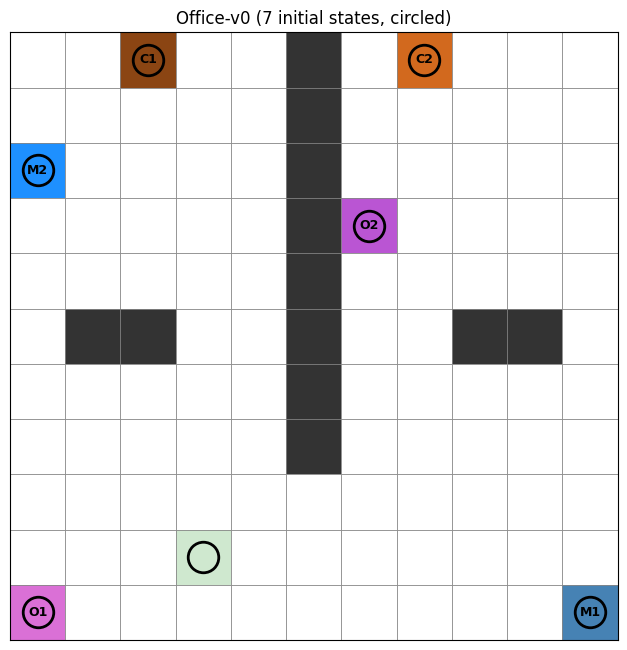

In [4]:
MAP = office_env.core.MAP
height, width = MAP.shape

color_map = {"X": "#333333", "_": "#cfe8cf", " ": "#ffffff"}
object_colors = {
    "C1": "#8B4513", "C2": "#D2691E",
    "M1": "#4682B4", "M2": "#1E90FF",
    "O1": "#DA70D6", "O2": "#BA55D3",
}
color_map.update(object_colors)


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            sym = MAP[r, c]
            color = color_map.get(sym, "#ffffff")
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if sym not in ("X", " ", "_"):
                ax.text(*cell_center(r, c), sym, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(width * 0.6, height * 0.6))
draw_domain(ax)
for s in office_env.core.initial:
    x, y = cell_center(*s)
    ax.plot(x, y, marker="o", markersize=22, markerfacecolor="none", markeredgecolor="black", markeredgewidth=2, zorder=5)
ax.set_title(f"Office-v0 ({len(office_env.core.initial)} initial states, circled)")
plt.tight_layout()
plt.show()

In [5]:
def office_step_deterministic(env, s, a):
    """One exact transition under Office's deterministic dynamics (random_act_prob=0.0)."""
    env.reset(options={"state": s})
    _, phi, terminated, _truncated, _ = env.step(a)
    return tuple(env.core.state), phi, terminated


office_states = [(r, c) for r in range(height) for c in range(width) if MAP[r, c] != "X"]
office_state_idx = {s: i for i, s in enumerate(office_states)}
n_office_states = len(office_states)
n_actions = office_env.action_space.n


def office_policy_iteration_from_any(w, gamma=GAMMA):
    """Ground truth for exit-state values: object cells are valid non-absorbing SOURCE
    states too (still terminal as destinations)."""
    policy = {s: 0 for s in office_states}
    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, policy[s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}
        stable = True
        for s in office_states:
            qs = []
            for a in range(n_actions):
                ns, phi, term = office_step_deterministic(office_env, s, a)
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_a = int(np.argmax(qs))
            stable &= best_a == policy[s]
            policy[s] = best_a
        if stable:
            return policy, V


def office_solve_task_exact(w, gamma=GAMMA):
    """Exact SF table Psi(s,a) for every action/state -- a separate vector-valued
    evaluation of the fixed policy (reusing the scalar V would silently broadcast it
    across all feature dims instead of the real vector, see notes/adaptive_basis.tex)."""
    policy, _ = office_policy_iteration_from_any(w, gamma)
    A, b = np.eye(n_office_states), np.zeros((n_office_states, d))
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, policy[s])
        b[i] = phi
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    V_vec = np.linalg.solve(A, b)
    V_vec = {s: V_vec[office_state_idx[s]] for s in office_states}

    psi = {}
    for s in office_states:
        table = np.zeros((n_actions, d))
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            table[a] = phi if term else phi + gamma * V_vec[ns]
        psi[s] = table
    return psi


def office_bellman_gap_from_any(w, V, gamma=GAMMA):
    """One full Bellman backup over the REAL 4-action space against a candidate V --
    no ground truth needed to trust a zero gap."""
    gaps = {}
    for s in office_states:
        qs = []
        for a in range(n_actions):
            ns, phi, term = office_step_deterministic(office_env, s, a)
            qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
        gaps[s] = max(qs) - V[s]
    return gaps


def own_greedy_actions_any(sf_table, w):
    return {s: int(np.argmax(sf_table[s] @ w)) for s in office_states}


def meta_policy_iteration_from_any(w, Pi_base, W_base, gamma=GAMMA):
    """Exact policy iteration over the meta-MDP whose actions are which of the k base
    policies' own action to take, solved for fresh-starting at ANY state."""
    own_actions = [own_greedy_actions_any(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    meta_policy = {s: 0 for s in office_states}

    while True:
        A, b = np.eye(n_office_states), np.zeros(n_office_states)
        for s in office_states:
            i = office_state_idx[s]
            ns, phi, term = office_step_deterministic(office_env, s, own_actions[meta_policy[s]][s])
            b[i] = phi @ w
            if not term:
                A[i, office_state_idx[ns]] -= gamma
        v = np.linalg.solve(A, b)
        V = {s: v[office_state_idx[s]] for s in office_states}

        stable = True
        for s in office_states:
            qs = []
            for j in range(len(Pi_base)):
                ns, phi, term = office_step_deterministic(office_env, s, own_actions[j][s])
                qs.append(phi @ w + (0.0 if term else gamma * V[ns]))
            best_j = int(np.argmax(qs))
            stable &= best_j == meta_policy[s]
            meta_policy[s] = best_j
        if stable:
            return meta_policy, V, own_actions


def meta_policy_iteration_certified(w, Pi_base, W_base, gamma=GAMMA, cert_tol=1e-6):
    """Compose from the CURRENT base; certify with one Bellman backup; fall back to an
    exact solve + grow the base if the certificate fails."""
    if Pi_base:
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        worst_gap = max(office_bellman_gap_from_any(w, V, gamma).values())
    else:
        worst_gap = np.inf
    if worst_gap > cert_tol:
        psi_new = office_solve_task_exact(w, gamma)
        Pi_base = Pi_base + [psi_new]
        W_base = W_base + [w]
        meta_policy, V, own_actions = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
        fell_back = True
    else:
        fell_back = False
    return meta_policy, V, own_actions, Pi_base, W_base, fell_back

In [6]:
def office_evaluate_policy_scalar(action_fn, w, gamma=GAMMA):
    """Exact scalar value of an arbitrary FIXED (state -> action) policy under w, via
    linear solve -- no ground-truth optimum needed."""
    A, b = np.eye(n_office_states), np.zeros(n_office_states)
    for s in office_states:
        i = office_state_idx[s]
        ns, phi, term = office_step_deterministic(office_env, s, action_fn(s))
        b[i] = phi @ w
        if not term:
            A[i, office_state_idx[ns]] -= gamma
    v = np.linalg.solve(A, b)
    return {s: v[office_state_idx[s]] for s in office_states}


def office_gpi_full_actions(Pi, w):
    """Standard GPI (Barreto et al., Eq. 4): argmax over the FULL action set, using
    max_j Psi_j(s,a).w for every action a -- not restricted to any policy's own action."""
    actions = {}
    for s in office_states:
        vals = [max(psi[s][a] @ w for psi in Pi) for a in range(n_actions)]
        actions[s] = int(np.argmax(vals))
    return actions


def office_election_actions(Pi_base, W_base, w):
    """One-shot restricted election: compare the k base policies' OWN actions by their
    SF value under the query weight w, pick the best per state -- a single greedy pass,
    NOT iterated. At k=1 there's nothing to elect between, so this is exactly pi(e_1)."""
    own_actions = [own_greedy_actions_any(sft, w_j) for sft, w_j in zip(Pi_base, W_base)]
    actions = {}
    for s in office_states:
        vals = [Pi_base[j][s][own_actions[j][s]] @ w for j in range(len(Pi_base))]
        best_j = int(np.argmax(vals))
        actions[s] = own_actions[best_j][s]
    return actions


def office_gpi_value(Pi_snapshot, w, gamma=GAMMA):
    actions = office_gpi_full_actions(Pi_snapshot, w)
    return office_evaluate_policy_scalar(lambda s: actions[s], w, gamma)


def office_election_value(Pi_base, W_base, w, gamma=GAMMA):
    actions = office_election_actions(Pi_base, W_base, w)
    return office_evaluate_policy_scalar(lambda s: actions[s], w, gamma)


def office_metapolicy_value(Pi_base, W_base, w, gamma=GAMMA):
    _, V, _ = meta_policy_iteration_from_any(w, Pi_base, W_base, gamma)
    return V


def office_mean_value(value_fn, test_weights):
    """value_fn(w) -> {state: scalar value}. Averages at office_env.core.initial
    (the 'different starting conditions'), then across all test weights."""
    vals = []
    for w in test_weights:
        V = value_fn(w)
        vals.append(np.mean([V[tuple(s0)] for s0 in office_env.core.initial]))
    return float(np.mean(vals))


N_TEST_WEIGHTS = 150
rng_w = np.random.default_rng(SEED)
test_weights = [rng_w.dirichlet(np.ones(d)) for _ in range(N_TEST_WEIGHTS)]

t0 = time.perf_counter()
optimal_mean = office_mean_value(lambda w: office_policy_iteration_from_any(w)[1], test_weights)
print(f"optimal_mean = {optimal_mean:.4f}  ({time.perf_counter() - t0:.1f}s, {N_TEST_WEIGHTS} test weights)")

t0 = time.perf_counter()
Pi_canon, W_canon = [], []
for i in range(d):
    w_i = np.zeros(d)
    w_i[i] = 1.0
    Pi_canon.append(office_solve_task_exact(w_i))
    W_canon.append(w_i)
print(f"solved the {d} canonical corner policies in {time.perf_counter() - t0:.1f}s")

optimal_mean = 0.3573  (91.4s, 150 test weights)


solved the 6 canonical corner policies in 4.8s


## Part 3 (new): cached transitions + fast/vectorized standard-GPI and envelope-GPI

The reference `office_gpi_full_actions`/`office_election_actions`/`office_metapolicy_value`
(cell above) call `office_step_deterministic`, which does a live gym env reset+step per
call -- fine for correctness, but its overhead would swamp any k-dependent timing
signal. These cells precompute the (policy-independent) transition table once and give
fully vectorized, numpy-only versions of both constructions, so the wall-clock
comparison isolates exactly the cost difference the theorem's Remark is about.

In [7]:
## Precompute the deterministic transition cache ONCE (doesn't depend on any policy or
## query weight) -- Office's office_step_deterministic() does a real gym env reset+step
## per call, so repeating it inside every per-query hot loop would confound the timing
## comparison with env-call overhead that has nothing to do with the k-dependence the
## theorem/cost claims are actually about. Both the standard-GPI and envelope-GPI "fast"
## paths below share this exact same cache, so the comparison stays fair.

NEXT_IDX = np.zeros((n_office_states, n_actions), dtype=int)
PHI_ARR = np.zeros((n_office_states, n_actions, d))
TERM_ARR = np.zeros((n_office_states, n_actions), dtype=bool)
for s in office_states:
    i = office_state_idx[s]
    for a in range(n_actions):
        ns, phi, term = office_step_deterministic(office_env, s, a)
        NEXT_IDX[i, a] = office_state_idx[ns]
        PHI_ARR[i, a] = phi
        TERM_ARR[i, a] = term

print(f"cached transition table: {n_office_states} states x {n_actions} actions x d={d}")


cached transition table: 109 states x 4 actions x d=6


In [8]:
## Fully vectorized (fair, apples-to-apples) standard-GPI and envelope-GPI, sharing the
## same cached transition table above. Both take a basis Pi_k, W_k (k canonical corner
## policies) and are the "fast path" used for both correctness checks and timing --
## office_gpi_full_actions / office_election_actions / office_metapolicy_value (cell 21,
## reused verbatim) remain the ground-truth reference implementations, used to
## cross-check these vectorized versions agree exactly.

def psi_stack(Pi_k):
    """(k, n_office_states, n_actions, d) array from the dict-of-dicts SF tables."""
    return np.stack([np.stack([psi[s] for s in office_states]) for psi in Pi_k], axis=0)


def own_action_idx_and_vec(Pi_k, W_k):
    """Each base policy's OWN action/SF-vector, independent of any query weight
    (depends only on the policy's own training weight W_k[j]) -- precomputed once per
    basis and reused across every query, exactly like Pi_base's tables themselves."""
    k = len(Pi_k)
    own_idx = np.zeros((k, n_office_states), dtype=int)
    own_vec = np.zeros((k, n_office_states, d))
    for j, (psi, wj) in enumerate(zip(Pi_k, W_k)):
        for s in office_states:
            i = office_state_idx[s]
            table = psi[s]
            a_star = int(np.argmax(table @ wj))
            own_idx[j, i] = a_star
            own_vec[j, i] = table[a_star]
    return own_idx, own_vec


def qhat_B_fast(w, Psi_stack):
    """Standard GPI's pool estimate, every (s,a): max_j Psi_j(s,a).w -- O(k|A|d)."""
    vals = Psi_stack @ w  # (k, n_office_states, n_actions)
    Qhat = vals.max(axis=0)  # (n_office_states, n_actions)
    pi_gpi_idx = Qhat.argmax(axis=1)
    return Qhat, pi_gpi_idx


def envelope_pi_star_fast(w, Pi_k, W_k, own_vec, gamma=GAMMA):
    """U_B(s) = max(V_meta(s), max_j V^{pi_j}(s)); pi_star = one full Bellman backup off
    U_B. V_meta still needs the real restricted policy-iteration solve (shared cost
    Certify-or-Grow already pays); the own-value part and the final backup are O(kd)
    and O(|A|d) respectively -- no k inside the |A|d part."""
    meta_policy, V_meta, _ = meta_policy_iteration_from_any(w, Pi_k, W_k, gamma)
    V_meta_arr = np.array([V_meta[s] for s in office_states])

    V_own = own_vec @ w  # (k, n_office_states)
    U = np.maximum(V_meta_arr, V_own.max(axis=0))  # (n_office_states,)

    Q_U = PHI_ARR @ w + gamma * (~TERM_ARR) * U[NEXT_IDX]  # (n_office_states, n_actions)
    pi_star_idx = Q_U.argmax(axis=1)
    return pi_star_idx, Q_U, U, V_meta


def evaluate_action_idx_policy(action_idx, w, gamma=GAMMA):
    """Realized value of a fixed (state -> action index) policy under the TRUE exact
    dynamics -- via the cached transition table, so this matches office_evaluate_policy_scalar
    exactly but without repeated live env calls."""
    A_mat, b = np.eye(n_office_states), np.zeros(n_office_states)
    for s in office_states:
        i = office_state_idx[s]
        a = int(action_idx[i])
        b[i] = PHI_ARR[i, a] @ w
        if not TERM_ARR[i, a]:
            A_mat[i, NEXT_IDX[i, a]] -= gamma
    v = np.linalg.solve(A_mat, b)
    return {s: v[office_state_idx[s]] for s in office_states}


print("Fast (cached, vectorized) standard-GPI and envelope-GPI defined.")


Fast (cached, vectorized) standard-GPI and envelope-GPI defined.


## Part 4: cross-check the fast path against the reference implementation

In [9]:
## Cross-check: the fast/cached/vectorized qhat_B_fast matches the reference,
## live-env office_gpi_full_actions exactly (same Q-values -> same greedy action, up to
## the deterministic domain's occasional action ties).

Psi_full_stack = psi_stack(Pi_canon)
own_idx_full, own_vec_full = own_action_idx_and_vec(Pi_canon, W_canon)

rng_cc = np.random.default_rng(123)
n_mismatch = 0
for _ in range(20):
    w_test = rng_cc.dirichlet(np.ones(d))
    Qhat_fast, pi_gpi_fast_idx = qhat_B_fast(w_test, Psi_full_stack)
    ref_actions = office_gpi_full_actions(Pi_canon, w_test)
    for s in office_states:
        i = office_state_idx[s]
        a_ref = ref_actions[s]
        a_fast = int(pi_gpi_fast_idx[i])
        if a_ref != a_fast and not np.isclose(Qhat_fast[i, a_ref], Qhat_fast[i, a_fast], atol=1e-9):
            n_mismatch += 1

print(f"cross-check over 20 random weights x {n_office_states} states: "
      f"{n_mismatch} genuine (non-tied) action mismatches between fast and reference GPI")


cross-check over 20 random weights x 109 states: 0 genuine (non-tied) action mismatches between fast and reference GPI


## Part 5: Theorem check on the real domain (`Q^{pi_star} >= Qhat_B`, every `(s,a)`)

In [10]:
## Theorem check on Office, full canonical basis (k=d=6): Q^{pi_star}(s,a) >= Qhat_B(s,a)
## for every (s,a), at a grid of new query weights.

rng_th = np.random.default_rng(7)
theorem_test_weights = [rng_th.dirichlet(np.ones(d)) for _ in range(100)]

worst_violation = -np.inf
worst_margin = -np.inf
n_violations = 0

for w in theorem_test_weights:
    Qhat, _ = qhat_B_fast(w, Psi_full_stack)
    pi_star_idx, Q_U, U, V_meta = envelope_pi_star_fast(w, Pi_canon, W_canon, own_vec_full)
    gap = Q_U - Qhat
    worst_violation = max(worst_violation, np.max(-gap))
    worst_margin = max(worst_margin, np.max(gap))
    if np.max(-gap) > 1e-6:
        n_violations += 1

print(f"Theorem check (Q_pi_star >= Qhat_B) on REAL Office (k={d} canonical basis), "
      f"{len(theorem_test_weights)} random test weights, {n_office_states} states each:")
print(f"  violations: {n_violations}  |  worst violation: {worst_violation:.8f}  |  "
      f"largest positive margin found: {worst_margin:.6f}")


Theorem check (Q_pi_star >= Qhat_B) on REAL Office (k=6 canonical basis), 100 random test weights, 109 states each:
  violations: 0  |  worst violation: 0.00000000  |  largest positive margin found: 0.000000


## Part 6: Honest realized-value comparison

Same honest check as `SFOLS/12`: the theorem only proves `pi_star` matches GPI's
*estimate*. Does GPI's own *realized* value ever beat `pi_star`'s, on the real domain?

In [11]:
## Honest realized-value comparison on Office, full canonical basis (k=d=6), START_STATE
## averaged over office_env.core.initial (matches office_mean_value's convention).

rng_rv = np.random.default_rng(2024)
rv_test_weights = [rng_rv.dirichlet(np.ones(d)) for _ in range(100)]


def start_mean(V):
    return float(np.mean([V[tuple(s0)] for s0 in office_env.core.initial]))


gpi_vals, star_vals, meta_vals, true_vals = [], [], [], []
for w in rv_test_weights:
    Qhat, pi_gpi_idx = qhat_B_fast(w, Psi_full_stack)
    pi_star_idx, Q_U, U, V_meta = envelope_pi_star_fast(w, Pi_canon, W_canon, own_vec_full)

    V_gpi = evaluate_action_idx_policy(pi_gpi_idx, w)
    V_star = evaluate_action_idx_policy(pi_star_idx, w)
    _, V_true = office_policy_iteration_from_any(w)

    gpi_vals.append(start_mean(V_gpi))
    star_vals.append(start_mean(V_star))
    meta_vals.append(start_mean(V_meta))
    true_vals.append(start_mean(V_true))

gpi_vals, star_vals, meta_vals, true_vals = map(np.array, (gpi_vals, star_vals, meta_vals, true_vals))
gpi_minus_star = gpi_vals - star_vals
n_gpi_wins = int(np.sum(gpi_minus_star > 1e-6))
n_star_wins = int(np.sum(gpi_minus_star < -1e-6))
n_ties = len(rv_test_weights) - n_gpi_wins - n_star_wins

print(f"Realized value (mean over initial states), {len(rv_test_weights)} test weights on "
      f"REAL Office (k={d} canonical basis):")
print(f"  pi_star  regret vs true optimum: mean={np.mean(true_vals - star_vals):.5f}  "
      f"max={np.max(true_vals - star_vals):.5f}")
print(f"  pi^GPI_B regret vs true optimum: mean={np.mean(true_vals - gpi_vals):.5f}  "
      f"max={np.max(true_vals - gpi_vals):.5f}")
print(f"  pi_meta  regret vs true optimum: mean={np.mean(true_vals - meta_vals):.5f}  "
      f"max={np.max(true_vals - meta_vals):.5f}")
print()
print(f"  GPI's realized value beats pi_star's realized value: {n_gpi_wins}/{len(rv_test_weights)} weights "
      f"(worst gap {np.max(gpi_minus_star):.5f})")
print(f"  pi_star's realized value beats GPI's realized value: {n_star_wins}/{len(rv_test_weights)} weights "
      f"(worst gap {np.max(-gpi_minus_star):.5f})")
print(f"  exact ties: {n_ties}/{len(rv_test_weights)}")


Realized value (mean over initial states), 100 test weights on REAL Office (k=6 canonical basis):
  pi_star  regret vs true optimum: mean=0.00000  max=0.00000
  pi^GPI_B regret vs true optimum: mean=0.00000  max=0.00000
  pi_meta  regret vs true optimum: mean=0.00000  max=0.00000

  GPI's realized value beats pi_star's realized value: 0/100 weights (worst gap 0.00000)
  pi_star's realized value beats GPI's realized value: 0/100 weights (worst gap 0.00000)
  exact ties: 100/100


## Part 7: cached, fully-vectorized metapolicy PI (fair timing baseline)

`meta_policy_iteration_from_any` (reused above, reference implementation) calls the
live gym env inside its policy-iteration loop -- fine for correctness, but its overhead
swamps any k-dependent signal at basis sizes beyond k=1. This cached replacement is
checked against the reference for exact agreement, then used for the timing sweep below
(this also isolates Certify-or-Grow's own existing metapolicy-solve cost fairly, not
just envelope-GPI's).

In [12]:
## The reference meta_policy_iteration_from_any (cell above) calls the LIVE gym env via
## office_step_deterministic() inside its policy-iteration loop -- for k=6 this made a
## single call take up to ~18s, completely swamping envelope-GPI's own incremental cost
## in the timing sweep below. This cached, vectorized replacement gives EXACTLY the same
## fixed point (it's the same restricted-PI operator, just reading from NEXT_IDX/PHI_ARR/
## TERM_ARR instead of resetting a live env every step) but removes the confound, which
## matters for measuring Certify-or-Grow's own shared cost fairly too, not just envelope-GPI's.

def own_transition_arrays(own_idx_k):
    """OWN_PHI[j,s], OWN_NEXT[j,s], OWN_TERM[j,s]: the transition under base policy j's
    OWN action at s -- basis-dependent only, precomputed once, reused across all queries."""
    k = own_idx_k.shape[0]
    rows = np.arange(n_office_states)
    OWN_PHI = PHI_ARR[rows[None, :], own_idx_k]      # (k, n_office_states, d)
    OWN_NEXT = NEXT_IDX[rows[None, :], own_idx_k]    # (k, n_office_states)
    OWN_TERM = TERM_ARR[rows[None, :], own_idx_k]    # (k, n_office_states)
    return OWN_PHI, OWN_NEXT, OWN_TERM


def meta_policy_iteration_fast(w, OWN_PHI, OWN_NEXT, OWN_TERM, gamma=GAMMA):
    k = OWN_PHI.shape[0]
    rows = np.arange(n_office_states)
    meta_policy = np.zeros(n_office_states, dtype=int)
    while True:
        phi_cur = OWN_PHI[meta_policy, rows]      # (n_office_states, d)
        next_cur = OWN_NEXT[meta_policy, rows]    # (n_office_states,)
        term_cur = OWN_TERM[meta_policy, rows]    # (n_office_states,)

        A_mat = np.eye(n_office_states)
        b = phi_cur @ w
        live = ~term_cur
        A_mat[rows[live], next_cur[live]] -= gamma
        V = np.linalg.solve(A_mat, b)

        Qs = OWN_PHI @ w + gamma * (~OWN_TERM) * V[OWN_NEXT]  # (k, n_office_states)
        new_meta_policy = Qs.argmax(axis=0)
        if np.array_equal(new_meta_policy, meta_policy):
            return meta_policy, V
        meta_policy = new_meta_policy


def envelope_pi_star_fast2(w, own_vec_k, OWN_PHI, OWN_NEXT, OWN_TERM, gamma=GAMMA):
    """Same construction as envelope_pi_star_fast, but using the cached meta-PI solve."""
    meta_policy, V_meta_arr = meta_policy_iteration_fast(w, OWN_PHI, OWN_NEXT, OWN_TERM, gamma)
    V_own = own_vec_k @ w
    U = np.maximum(V_meta_arr, V_own.max(axis=0))
    Q_U = PHI_ARR @ w + gamma * (~TERM_ARR) * U[NEXT_IDX]
    pi_star_idx = Q_U.argmax(axis=1)
    return pi_star_idx, Q_U, U, V_meta_arr


# sanity: fast meta-PI agrees with the reference (live-env) one
w_check = np.random.default_rng(11).dirichlet(np.ones(d))
meta_ref, V_ref, _ = meta_policy_iteration_from_any(w_check, Pi_canon, W_canon)
own_idx_full2, own_vec_full2 = own_action_idx_and_vec(Pi_canon, W_canon)
OWN_PHI_full, OWN_NEXT_full, OWN_TERM_full = own_transition_arrays(own_idx_full2)
meta_fast, V_fast = meta_policy_iteration_fast(w_check, OWN_PHI_full, OWN_NEXT_full, OWN_TERM_full)
V_ref_arr = np.array([V_ref[s] for s in office_states])
print("fast meta-PI matches reference V exactly:", np.allclose(V_ref_arr, V_fast, atol=1e-8),
      f"(max abs diff {np.max(np.abs(V_ref_arr - V_fast)):.2e})")


fast meta-PI matches reference V exactly: True (max abs diff 0.00e+00)


## Part 8: real wall-clock cost vs basis size k

k=1: GPI=   3.65 ms  |  envelope(total)=  52.04 ms  |  meta-PI alone=  42.37 ms  |  envelope(incremental)=   9.67 ms  |  speedup(incremental)= 0.38x  |  speedup(total)=0.070x


k=2: GPI=   5.25 ms  |  envelope(total)= 152.79 ms  |  meta-PI alone= 136.06 ms  |  envelope(incremental)=  16.72 ms  |  speedup(incremental)= 0.31x  |  speedup(total)=0.034x


k=3: GPI=   6.98 ms  |  envelope(total)= 149.46 ms  |  meta-PI alone= 148.22 ms  |  envelope(incremental)=   1.24 ms  |  speedup(incremental)= 5.61x  |  speedup(total)=0.047x


k=4: GPI=   8.70 ms  |  envelope(total)= 153.44 ms  |  meta-PI alone= 144.24 ms  |  envelope(incremental)=   9.20 ms  |  speedup(incremental)= 0.95x  |  speedup(total)=0.057x


k=5: GPI=  10.39 ms  |  envelope(total)= 147.26 ms  |  meta-PI alone= 145.91 ms  |  envelope(incremental)=   1.35 ms  |  speedup(incremental)= 7.72x  |  speedup(total)=0.071x


k=6: GPI=  12.28 ms  |  envelope(total)= 293.80 ms  |  meta-PI alone= 279.14 ms  |  envelope(incremental)=  14.65 ms  |  speedup(incremental)= 0.84x  |  speedup(total)=0.042x


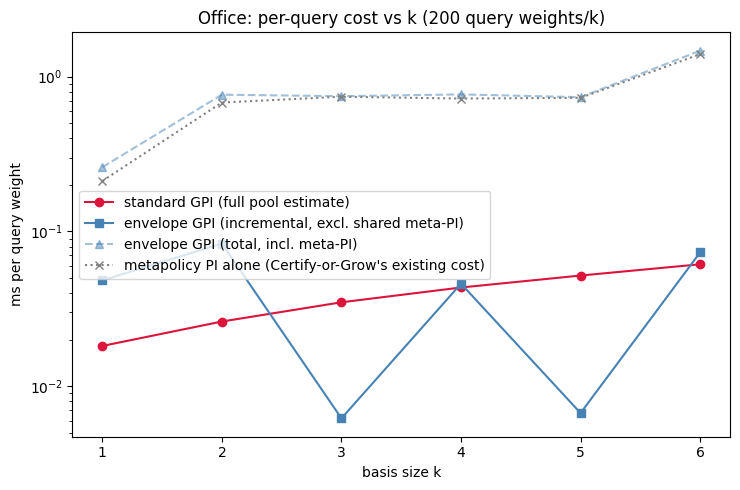

In [13]:
## Real wall-clock cost vs k, on Office (bigger action set / feature dim than DST, and a
## basis that actually grows to k=d=6 canonical corners -- unlike DST, where
## Certify-or-Grow's real basis stayed at k=2 and never exercised the k-dependence).
## Both paths share the identical cached transition table and the cached meta-PI solve
## (cell above), so the "incremental" cost of envelope-GPI on top of the shared
## metapolicy machinery Certify-or-Grow already pays for is now measured cleanly.

N_TIMING_WEIGHTS = 200
timing_weights = [np.random.default_rng(999).dirichlet(np.ones(d)) for _ in range(N_TIMING_WEIGHTS)]

ks = np.arange(1, d + 1)
t_gpi_by_k, t_env_by_k, t_meta_by_k, t_env_incr_by_k = [], [], [], []

for k in ks:
    Pi_k, W_k = Pi_canon[:k], W_canon[:k]
    Psi_k_stack = psi_stack(Pi_k)
    own_idx_k, own_vec_k = own_action_idx_and_vec(Pi_k, W_k)
    OWN_PHI_k, OWN_NEXT_k, OWN_TERM_k = own_transition_arrays(own_idx_k)

    t0 = time.perf_counter()
    for w in timing_weights:
        qhat_B_fast(w, Psi_k_stack)
    t_gpi = time.perf_counter() - t0

    t0 = time.perf_counter()
    for w in timing_weights:
        envelope_pi_star_fast2(w, own_vec_k, OWN_PHI_k, OWN_NEXT_k, OWN_TERM_k)
    t_env = time.perf_counter() - t0

    t0 = time.perf_counter()
    for w in timing_weights:
        meta_policy_iteration_fast(w, OWN_PHI_k, OWN_NEXT_k, OWN_TERM_k)
    t_meta = time.perf_counter() - t0

    t_gpi_by_k.append(t_gpi)
    t_env_by_k.append(t_env)
    t_meta_by_k.append(t_meta)
    t_env_incr_by_k.append(t_env - t_meta)

    print(f"k={k}: GPI={t_gpi*1000:7.2f} ms  |  envelope(total)={t_env*1000:7.2f} ms  |  "
          f"meta-PI alone={t_meta*1000:7.2f} ms  |  envelope(incremental)={((t_env - t_meta)*1000):7.2f} ms  |  "
          f"speedup(incremental)={t_gpi / max(t_env - t_meta, 1e-9):5.2f}x  |  "
          f"speedup(total)={t_gpi / t_env:5.3f}x")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(ks, np.array(t_gpi_by_k) * 1000 / N_TIMING_WEIGHTS, marker="o", color="crimson",
        label="standard GPI (full pool estimate)")
ax.plot(ks, np.array(t_env_incr_by_k) * 1000 / N_TIMING_WEIGHTS, marker="s", color="steelblue",
        label="envelope GPI (incremental, excl. shared meta-PI)")
ax.plot(ks, np.array(t_env_by_k) * 1000 / N_TIMING_WEIGHTS, marker="^", ls="--", color="steelblue", alpha=0.5,
        label="envelope GPI (total, incl. meta-PI)")
ax.plot(ks, np.array(t_meta_by_k) * 1000 / N_TIMING_WEIGHTS, marker="x", ls=":", color="gray",
        label="metapolicy PI alone (Certify-or-Grow's existing cost)")
ax.set_xlabel("basis size k")
ax.set_ylabel("ms per query weight")
ax.set_yscale("log")
ax.set_title(f"Office: per-query cost vs k ({N_TIMING_WEIGHTS} query weights/k)")
ax.set_xticks(ks)
ax.legend()
plt.tight_layout()
plt.show()
